## Convolution and Green's Functions

Recall the Green's function for the Laplace equation:

$$ \Delta G(x) = \delta(x)$$

This is a solution to Poisson's equation

$$
\Delta u = f    
$$

in the sense that $u = (G * f)$

where $*$ is the convolution operator satisfying, 

$$G * f  = \int_{\mathbb{R}^n} G(y-x) f(y) dy$$

In [2]:
import matplotlib.pyplot as plt
import scipy
import numpy as np

For a 1D, the Green's function may be given as, 

$$
G(x) = |x|/2
$$

Let us demonstrate that this is indeed a Green's function. 

In [3]:
def Green_line(x):
    return np.abs(x)/2

def Green_line_deriv(x:float):
    if x > 0:
        return 1
    if x < 0:
        return -1

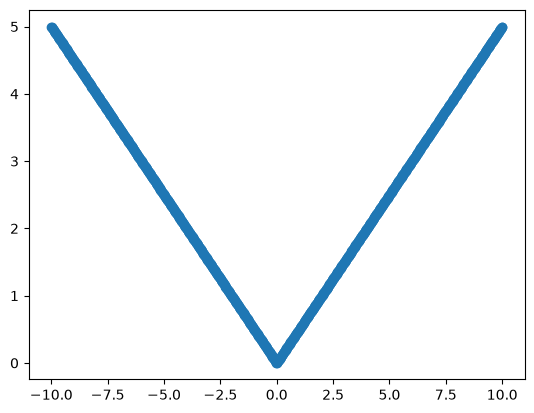

In [4]:
x = np.linspace(-10,10,1000)
x = x[x!=0]
pi = np.pi
fig, ax = plt.subplots()
G = np.zeros_like(x)



for i in range(x.shape[0]):
    G[i] = Green_line(x[i])
ax.scatter(x,G)



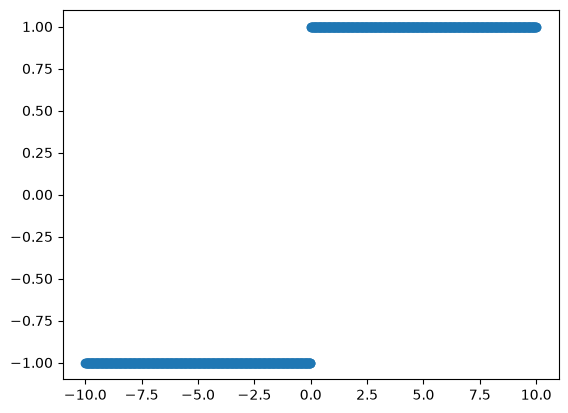

In [5]:
fig, ax = plt.subplots()
G_d = np.zeros_like(x)
for i in range(x.shape[0]):
    G_d[i] = Green_line_deriv(x[i])
ax.scatter(x,G_d)

Clearly, the derivative of this function is $\delta(x)$. Therefore, 

$$G''(x) = \delta(x)$$

So $G$ is a Green's function for the 1D poisson problem. 

## Computing the solution via Convolution

For a particular example, we choose 

$$
f(x) = \frac{1}{\sqrt{2 \pi \sigma^2}} exp({\frac{-x^2}{2\sigma^2}})
$$

This is the Normal/Gaussian probability density function with a mean of 0. Then, essentially by definition, 

$$
\Delta (G * f) = f,
$$

So we choose $u = G * f = \int_{-\infty}^\infty G(x-y) f(y) dy$

$$
u(x) = G * f = \int_{-\infty}^\infty \frac{|x-y|}{2} \frac{1}{\sqrt{2 \pi \sigma^2}} exp({\frac{-y^2}{2\sigma^2}})
$$

This function behaves differently depending on whether $x > y$. 

$$
u(x) = G * f = \int_{-\infty}^x \frac{x-y}{2} \frac{1}{\sqrt{2 \pi \sigma^2}} exp({\frac{-y^2}{2\sigma^2}}) + \int_{x}^\infty \frac{y-x}{2} \frac{1}{\sqrt{2 \pi \sigma^2}} exp({\frac{-y^2}{2\sigma^2}})
$$

These integrals are essentially similar. Note that $x$, despite ultimately being the variable of u, is not a variable of integration. Taking the pieces involving $x$ gives a form [familar to those with statistical backgrounds](https://statproofbook.github.io/P/norm-cdf.html).

$$
 \frac{x}{2} \int_{-\infty}^x  \frac{1}{\sqrt{2 \pi \sigma^2}} exp({\frac{-y^2}{2\sigma^2}}) - \frac{x}{2} \int_{x}^\infty \frac{1}{\sqrt{2 \pi \sigma^2}} exp({\frac{-y^2}{2\sigma^2}})
$$

These integrals can be written in a form befitting their statistical heritage. In general, it can be shown $\dagger$ that,

$$
u(x) = x* (CDF(x, \sigma) - 0.5) + \sigma^2 PDF(x, \sigma)
$$

Where CDF and PDF refer to the normal cumulative distributional and probability density functions.

($\dagger$ By you, dear reader!)


In [6]:
from scipy.integrate import trapezoid
from scipy.stats import norm

def u_exact(x, sigma):
    return x*(norm.cdf(x, scale=sigma) - 0.5) + sigma**2 * norm.pdf(x, scale=sigma)

def u_conv(x, sigma, y):
    """"Trapezoidal rule"""
    K = Green_line(x[:, None] - y[None, :]) * norm.pdf(y, scale=sigma)[None, :]   # K[i, j] = G(x_i - y_j) f(y_j)
    return trapezoid(K, y, axis=1)

In [7]:
from greens_widgets import sweep_widget, solution_widget

In [8]:
sweep_widget(Green_line, u_exact)

In [9]:
solution_widget(Green_line, u_exact, u_conv)

Questions to think about:

1) Is the solution to the Poisson problem unique? 
2) What happens as $\sigma \to 0$?
3) What happens when $x \to +/-\infty$?
4) What happens when $y \to +/-\infty$?
5) When is the numerical integration least accurate? 